# Panel de modelos · estado general

Vista de conjunto de todos los modelos del equipo y del stacking. **Ejecutar de arriba abajo (Run All).**

1. Comprueba qué modelos tienen `oof/<m>.csv` y `preds/<m>.csv`. Los que falten se **generan** con su script (si `GENERAR = True`).
2. Rehace el stacking si está desfasado (algún modelo es más nuevo que `oof/stack_meta.csv`) o si cambia la lista `STACK_MODELOS`.
3. Evalúa cada modelo solo y los stacks: CV top-3, por fold, por controlador, por tipo de tarea correcta, gemelos assume/entry.
4. Mira cuánto se parecen los modelos (correlación de aciertos y techo "algún modelo acierta").
5. Revisa las submissions de `submissions/`.
6. Compara con los modelos de `futuro/` (usan otros snapshots); genera los que falten y rehace su stacking si está desfasado.
7. Resume.

Todo con `Data/folds.csv` y `cv/metric.py`. Las secciones 1–5 usan los modelos de `oof/` (regla 1); los de `futuro/` van aparte en la sección 6 con su propio stacking.

In [1]:
import sys, json, subprocess, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "Data"
sys.path.insert(0, str(ROOT / "cv"))
from metric import hits, labels

VENV = ROOT / ".venv" / "bin" / "python"
PY = str(VENV) if VENV.exists() else sys.executable   # los scripts necesitan lightgbm/torch del .venv
GENERAR = True                                     # generar los modelos que falten (puede tardar mucho)
STACK_MODELOS = ["lgb_adri", "nn_tf_v2", "types"]  # modelos que entran en el stacking
REHACER_STACK = "auto"                             # "auto" (si está desfasado), True o False
pd.set_option("display.width", 200)

# Cómo se genera cada modelo (oof/<m>.csv + preds/<m>.csv). Los pasos se ejecutan en orden desde la raíz del repo.
GENERADORES = {
    "lgb_adri": [["-m", "jupyter", "nbconvert", "--to", "notebook", "--execute", "notebooks/LGB_adri.ipynb",
                  "--output-dir", "models", "--output", "LGB_adri_ejecutado", "--ExecutePreprocessor.timeout=-1"]],
    "nn_tf_v2": [["src/m_nn.py", "--name", "nn_tf_v2", "--ls", "0", "--layers", "4", "--lr", "0.0005"]],
    "types":    [["hierarchical/m_types.py"]],
    "linear":   [["linear/m_linear.py"]],
    "clogit":   [["src/features.py"], ["src/m_clogit.py"]],   # clogit necesita models/features.parquet
}
AUTOR = {"lgb_adri": "Adri", "nn_tf_v2": "Pablo", "types": "Juanma", "linear": "Juanma", "clogit": "Juanma"}

## 1. Modelos disponibles (y generación de los que falten)

In [2]:
def tiene(m):
    return (ROOT / "oof" / f"{m}.csv").exists() and (ROOT / "preds" / f"{m}.csv").exists()

def ejecutar(args):
    print("  $ python", " ".join(args), flush=True)
    t = time.time()
    r = subprocess.run([PY, *args], cwd=ROOT, capture_output=True, text=True)
    cola = (r.stdout + r.stderr).strip().splitlines()[-6:]
    print("    " + "\n    ".join(cola))
    print(f"    -> código {r.returncode} en {time.time() - t:.0f}s", flush=True)
    return r.returncode == 0

if (ROOT / "models" / "features.parquet").exists() is False:
    GENERADORES["clogit"] = [["src/features.py"], ["src/m_clogit.py"]]
elif "clogit" in GENERADORES:
    GENERADORES["clogit"] = [["src/m_clogit.py"]]

estado = {}
for m, pasos in GENERADORES.items():
    if tiene(m):
        estado[m] = "leído"
    elif GENERAR:
        print(f"Generando {m}...")
        ok = all(ejecutar(p) for p in pasos)
        estado[m] = "generado" if ok and tiene(m) else "ERROR al generar"
    else:
        estado[m] = "falta (GENERAR = False)"

# modelos de otros que hayan aparecido en oof/ sin generador conocido
otros = sorted(p.stem for p in (ROOT / "oof").glob("*.csv")
               if not p.stem.startswith("stack") and p.stem not in GENERADORES and tiene(p.stem))
for m in otros:
    estado[m] = "leído (sin generador en el panel)"

MODELOS = [m for m, e in estado.items() if tiene(m)]
pd.DataFrame({"estado": estado,
              "modificado": {m: time.strftime("%d/%m %H:%M", time.localtime((ROOT / "oof" / f"{m}.csv").stat().st_mtime))
                             if tiene(m) else "" for m in estado},
              "autor": {m: AUTOR.get(m, "?") for m in estado}})

,estado,modificado,autor
lgb_adri,leído,20/10 19:20,Adri
nn_tf_v2,leído,20/10 18:08,Pablo
types,leído,20/10 18:06,Juanma
linear,leído,20/10 18:19,Juanma
clogit,leído,20/10 18:44,Juanma


## 2. Stacking
Se rehace con `stacking/stack.py` si algún modelo es más nuevo que el stack guardado o si cambió `STACK_MODELOS` (la composición del último stack se apunta en `models/ultimo_stack.json`).

In [3]:
REG = ROOT / "models" / "ultimo_stack.json"
st_oof = ROOT / "oof" / "stack_meta.csv"
faltan = [m for m in STACK_MODELOS if m not in MODELOS]
assert not faltan, f"faltan modelos para el stacking: {faltan}"

previo = json.loads(REG.read_text()) if REG.exists() else {}
mt_modelos = max((ROOT / "oof" / f"{m}.csv").stat().st_mtime for m in STACK_MODELOS)
motivos = []
if not st_oof.exists() or not (ROOT / "preds" / "stack_meta.csv").exists():
    motivos.append("no existe")
else:
    if st_oof.stat().st_mtime < mt_modelos:
        motivos.append("algún modelo es más nuevo")
    if previo.get("modelos") != STACK_MODELOS:
        motivos.append(f"composición distinta (antes: {previo.get('modelos', 'desconocida')})")
rehacer = REHACER_STACK is True or (REHACER_STACK == "auto" and motivos)
print("Stack guardado:", previo or "sin registro", "\nMotivos para rehacer:", motivos or "ninguno")

if rehacer:
    print(f"Rehaciendo stacking con {STACK_MODELOS} (~5 min)...")
    if ejecutar(["-W", "ignore", "stacking/stack.py", *STACK_MODELOS]):
        REG.write_text(json.dumps({"modelos": STACK_MODELOS, "cuando": time.strftime("%d/%m %H:%M")}))
    else:
        print("ERROR: el stacking no se ha rehecho; los stack_* que se evalúan abajo son los antiguos.")
else:
    print("Se usa el stacking guardado.")
STACK_REAL = json.loads(REG.read_text())["modelos"] if REG.exists() else None   # composición del stack evaluado
STACKS = [s for s in ("stack_avg", "stack_meta") if tiene(s)]

Stack guardado: {'modelos': ['lgb_adri', 'nn_tf_v2', 'types'], 'cuando': '20/10 19:44'} 
Motivos para rehacer: ninguno
Se usa el stacking guardado.


## 3. Evaluación: cada modelo solo y los stacks

In [4]:
lab = labels()                                      # sample_id, target, atco, fold
info = pd.concat([pd.read_csv(DATA / f"{f}.csv", usecols=["sample_id", "row_index", "target_index", "task_index", "l_twin_AE"])
                  for f in ("train", "validation")])
info = info[info.target_index == 1].set_index("sample_id")[["task_index", "l_twin_AE"]]
TIPOS = {0: "entry_conflict_res", 1: "exit_conflict_res", 2: "entry_coord", 3: "exit_coord", 4: "assume",
         5: "transfer", 6: "conflict_res", 7: "non_conformance", 8: "qos", 9: "entry_cond", 10: "exit_cond",
         11: "aircraft_req", 12: "zone_conflict", 13: "return_to_route"}

TODOS = MODELOS + STACKS
H = pd.DataFrame({m: hits(pd.read_csv(ROOT / "oof" / f"{m}.csv")) for m in TODOS})   # 1/0 por muestra
H = H.join(lab.set_index("sample_id")[["atco", "fold"]]).join(info)
assert len(H) == len(lab) and H[TODOS].notna().all().all(), "algún OOF no cubre todas las muestras"

por_fold = H.groupby("fold")[TODOS].mean().T
por_atco = H.groupby("atco")[TODOS].mean().T
resumen = pd.DataFrame({
    "CV top-3": H[TODOS].mean(),
    "std folds": por_fold.std(axis=1),
    "peor fold": por_fold.min(axis=1),
    "peor atco": por_atco.min(axis=1),
    "media por atco": por_atco.mean(axis=1),
    "atco 020 (val)": por_atco[20],
    "en stack": ["sí" if m in STACK_MODELOS else ("—" if m in STACKS else "no") for m in TODOS],
}).sort_values("CV top-3", ascending=False)
mejor_solo = resumen.drop(STACKS, errors="ignore")["CV top-3"].idxmax()
resumen["vs mejor solo"] = resumen["CV top-3"] - resumen.loc[mejor_solo, "CV top-3"]
print("atco 020 (val) = acierto OOF en las 399 muestras de validación del controlador 020 (el del LB público; muy ruidoso).")
resumen.style.format({c: "{:.4f}" for c in resumen.columns if c != "en stack"} | {"vs mejor solo": "{:+.4f}"}) \
    .background_gradient(cmap="Blues", subset=["CV top-3"])

atco 020 (val) = acierto OOF en las 399 muestras de validación del controlador 020 (el del LB público; muy ruidoso).


,CV top-3,std folds,peor fold,peor atco,media por atco,atco 020 (val),en stack,vs mejor solo
stack_meta,0.6600,0.0249,0.6347,0.5802,0.6686,0.7594,—,+0.0031
lgb_adri,0.6569,0.0290,0.6258,0.5704,0.6674,0.7794,sí,+0.0000
stack_avg,0.6562,0.0321,0.6197,0.5712,0.6654,0.7343,—,-0.0008
linear,0.6323,0.0312,0.5909,0.5423,0.6366,0.6767,no,-0.0246
nn_tf_v2,0.6279,0.0278,0.6011,0.5664,0.6329,0.7168,sí,-0.0290
types,0.6054,0.0144,0.5897,0.5319,0.6119,0.7043,sí,-0.0515
clogit,0.5255,0.0207,0.4996,0.4447,0.5359,0.6090,no,-0.1314


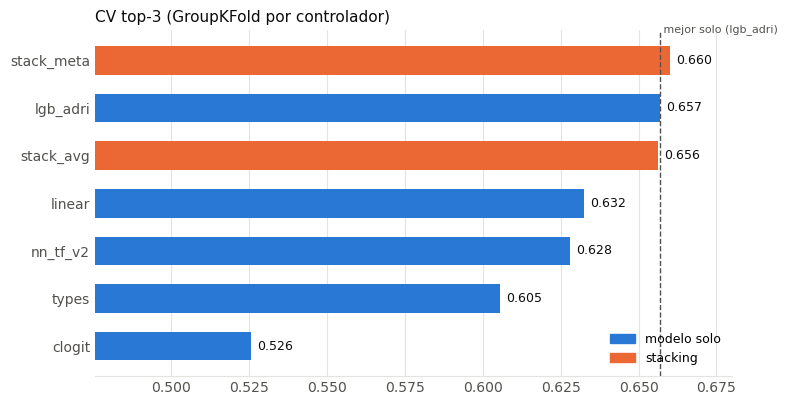

In [5]:
# Gráfico: CV top-3 por modelo. Azul = modelo solo, naranja = stacking.
AZUL, NARANJA, TINTA, TINTA2, REJILLA = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
r = resumen["CV top-3"].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.45 * len(r) + 1))
ax.barh(r.index, r.values, height=0.6, color=[NARANJA if m in STACKS else AZUL for m in r.index])
lo = max(0, r.min() - 0.05)
ax.set_xlim(lo, r.max() + 0.02)
for y, v in enumerate(r.values):
    ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=9, color=TINTA)
ax.axvline(r[mejor_solo], color=TINTA2, lw=1, ls="--")
ax.text(r[mejor_solo], len(r) - 0.4, f" mejor solo ({mejor_solo})", fontsize=8, color=TINTA2)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(REJILLA)
ax.tick_params(colors=TINTA2, length=0)
ax.grid(axis="x", color=REJILLA, lw=0.8); ax.set_axisbelow(True)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="modelo solo"), Patch(color=NARANJA, label="stacking")],
          frameon=False, loc="lower right", fontsize=9)
ax.set_title("CV top-3 (GroupKFold por controlador)", loc="left", color=TINTA, fontsize=11)
plt.tight_layout(); plt.show()

### Por fold y por controlador
Cada fold es un grupo de controladores. Lo que importa para el privado (controlador 023, nuevo) es que el modelo no se hunda en ningún controlador.

In [6]:
por_fold.loc[resumen.index].style.format("{:.3f}").background_gradient(cmap="Blues", axis=None)

fold,0,1,2,3,4
stack_meta,0.701,0.656,0.662,0.635,0.648
lgb_adri,0.704,0.659,0.654,0.626,0.643
stack_avg,0.707,0.656,0.658,0.620,0.641
linear,0.673,0.615,0.648,0.591,0.636
nn_tf_v2,0.667,0.606,0.645,0.601,0.622
types,0.629,0.603,0.604,0.590,0.602
clogit,0.557,0.525,0.530,0.518,0.500


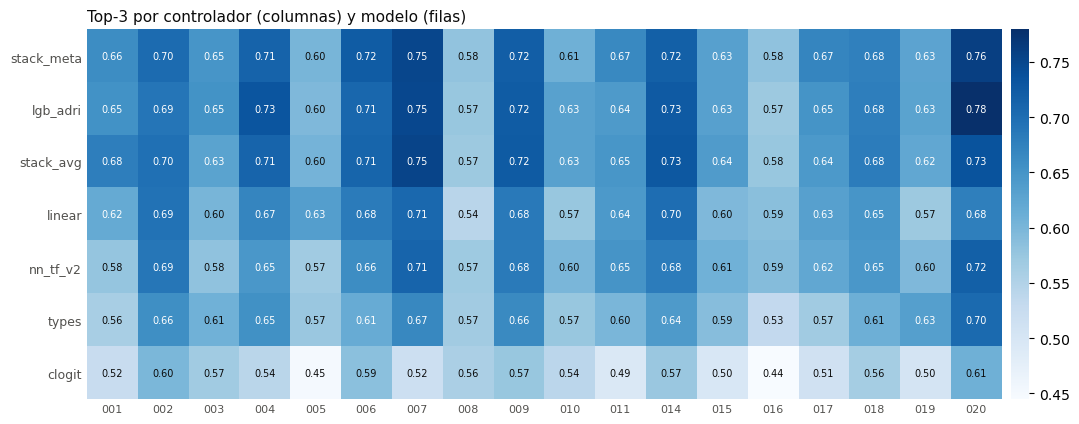

In [7]:
orden = resumen.index
fig, ax = plt.subplots(figsize=(1 + 0.55 * por_atco.shape[1], 0.45 * len(orden) + 1.2))
M = por_atco.loc[orden]
im = ax.imshow(M.values, cmap="Blues", aspect="auto", vmin=M.values.min(), vmax=M.values.max())
ax.set_xticks(range(M.shape[1]), [f"{a:03d}" for a in M.columns], fontsize=8, color=TINTA2)
ax.set_yticks(range(M.shape[0]), M.index, fontsize=9, color=TINTA2)
mid = (M.values.min() + M.values.max()) / 2
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if M.values[i, j] > mid else TINTA)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Top-3 por controlador (columnas) y modelo (filas)", loc="left", color=TINTA, fontsize=11)
plt.colorbar(im, ax=ax, fraction=0.02, pad=0.01).outline.set_visible(False)
plt.tight_layout(); plt.show()

### Por tipo de la tarea correcta
¿En qué tipo de tarea acierta cada modelo? `n` = muestras cuya respuesta es de ese tipo. Los tipos con pocas muestras son ruidosos.

In [8]:
pt = H.groupby("task_index")[list(orden)].mean().T
pt.columns = [TIPOS[t] for t in pt.columns]
n_t = H.task_index.value_counts().rename(lambda t: TIPOS[t])
pt.loc["n"] = n_t.reindex(pt.columns).values
cols = list(n_t[n_t >= 30].index)              # solo tipos con >= 30 muestras
pt[cols].style.format("{:.3f}").format("{:.0f}", subset=pd.IndexSlice["n", :]) \
    .background_gradient(cmap="Blues", axis=0, subset=pd.IndexSlice[list(orden), cols])

,transfer,assume,zone_conflict,entry_coord,return_to_route,exit_coord,exit_cond,conflict_res,qos,exit_conflict_res,non_conformance,entry_conflict_res
stack_meta,0.857,0.823,0.740,0.436,0.475,0.089,0.156,0.405,0.156,0.188,0.605,0.032
lgb_adri,0.863,0.836,0.710,0.389,0.499,0.094,0.188,0.318,0.163,0.162,0.605,0.065
stack_avg,0.871,0.838,0.736,0.359,0.482,0.071,0.156,0.292,0.163,0.142,0.558,0.065
linear,0.847,0.750,0.774,0.317,0.456,0.068,0.114,0.454,0.144,0.228,0.616,0.000
nn_tf_v2,0.837,0.802,0.755,0.291,0.374,0.051,0.127,0.326,0.167,0.198,0.605,0.065
types,0.861,0.820,0.636,0.269,0.353,0.060,0.080,0.126,0.109,0.137,0.337,0.000
clogit,0.790,0.736,0.572,0.013,0.315,0.000,0.004,0.303,0.000,0.071,0.035,0.000
n,3527,3366,2121,1068,937,745,448,390,257,197,86,31


In [9]:
tw = H.groupby("l_twin_AE")[list(orden)].mean().T
tw.columns = [f"l_twin_AE={int(c)}" for c in tw.columns]
tw["n gemelo"] = int((H.l_twin_AE == 1).sum())
print("Acierto según si la respuesta es de un avión con assume + entry_coordination a la vez (caso difícil):")
tw.style.format("{:.3f}", subset=tw.columns[:-1])

Acierto según si la respuesta es de un avión con assume + entry_coordination a la vez (caso difícil):


,l_twin_AE=0,l_twin_AE=1,n gemelo
stack_meta,0.641,0.704,3940
lgb_adri,0.637,0.703,3940
stack_avg,0.639,0.696,3940
linear,0.638,0.619,3940
nn_tf_v2,0.618,0.651,3940
types,0.583,0.658,3940
clogit,0.522,0.534,3940


## 4. ¿Cuánto se parecen los modelos?
Si dos modelos aciertan en las mismas muestras, combinarlos aporta poco. El **techo** es la fracción de muestras en las que *algún* modelo acierta: el stacking no puede superarlo (solo acercarse).

In [10]:
C = H[MODELOS].corr()
display(C.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0.4, vmax=1))
techo = H[MODELOS].max(axis=1).mean()
techo_stack = H[STACK_MODELOS].max(axis=1).mean()
todos_fallan = 1 - techo
print(f"Algún modelo acierta (techo, todos los modelos): {techo:.3f}")
print(f"Algún modelo del stack acierta ({', '.join(STACK_MODELOS)}): {techo_stack:.3f}")
print(f"Todos fallan: {todos_fallan:.3f}  -> ahí no hay nada que combinar; hacen falta features o modelos nuevos")
# aporte exclusivo: muestras que solo acierta ese modelo
excl = {m: int(((H[m] == 1) & (H[[o for o in MODELOS if o != m]].sum(axis=1) == 0)).sum()) for m in MODELOS}
pd.Series(excl, name="muestras que solo acierta este modelo").sort_values(ascending=False).to_frame()

,lgb_adri,nn_tf_v2,types,linear,clogit
lgb_adri,1.00,0.70,0.68,0.66,0.54
nn_tf_v2,0.70,1.00,0.61,0.75,0.53
types,0.68,0.61,1.00,0.57,0.57
linear,0.66,0.75,0.57,1.00,0.52
clogit,0.54,0.53,0.57,0.52,1.00


Algún modelo acierta (techo, todos los modelos): 0.787
Algún modelo del stack acierta (lgb_adri, nn_tf_v2, types): 0.744
Todos fallan: 0.213  -> ahí no hay nada que combinar; hacen falta features o modelos nuevos


,muestras que solo acierta este modelo
linear,264
clogit,252
lgb_adri,250
types,236
nn_tf_v2,139


## 5. Submissions
Comprueba el formato de cada `submissions/sub_*.csv` (1863 muestras, 3 `row_index` válidos y distintos) y le pone la CV de su OOF. **Nadie sube salvo Juanma.** No se sube nada de `submissions/future/` ni de `futuro/`.

In [11]:
test = pd.read_csv(DATA / "test.csv", usecols=["sample_id", "row_index"])
validos = test.groupby("sample_id").row_index.apply(set)
filas = []
for p in sorted((ROOT / "submissions").glob("sub_*.csv")):
    s = pd.read_csv(p, dtype={"prediction": str})
    ok = (len(s) == len(validos) and set(s.sample_id) == set(validos.index) and
          all(len(set(map(int, x.split()))) == 3 and set(map(int, x.split())) <= validos[i]
              for i, x in zip(s.sample_id, s.prediction)))
    m = p.stem[4:]
    filas.append({"submission": p.name, "formato": "OK" if ok else "MAL",
                  "CV top-3": resumen["CV top-3"].get(m, np.nan),
                  "modificado": time.strftime("%d/%m %H:%M", time.localtime(p.stat().st_mtime))})
subs = pd.DataFrame(filas).sort_values("CV top-3", ascending=False)
subs.style.format({"CV top-3": "{:.4f}"}, na_rep="—")

,submission,formato,CV top-3,modificado
5,sub_stack_meta.csv,OK,0.6600,20/10 19:44
1,sub_lgb_adri.csv,OK,0.6569,20/10 19:20
4,sub_stack_avg.csv,OK,0.6562,20/10 19:44
2,sub_linear.csv,OK,0.6323,20/10 18:19
3,sub_nn_tf_v2.csv,OK,0.6279,20/10 18:08
6,sub_types.csv,OK,0.6054,20/10 18:06
0,sub_clogit.csv,OK,0.5255,20/10 18:44


## 6. Modelos con otros snapshots (`futuro/`)
Usan información de otros snapshots de la sesión (pasado y futuro), es decir, no cumplen la regla 1. Están en `futuro/oof|preds|submissions`.
Mismos folds (`Data/folds.csv`), así que la CV es comparable.

Si falta alguno y `GENERAR_FUTURO = True`, se genera con su script (ver `futuro/README.md`). El stacking futuro (`stack.py --futuro`, modelos de `oof/` + `futuro/oof/`)
se rehace si algún modelo es más nuevo que él. Se muestra como `stack_*_futuro`.

In [12]:
GENERAR_FUTURO = True       # generar los modelos futuros que falten (lento)
REHACER_STACK_FUT = "auto"   # "auto" (si está desfasado), True o False
FUT = ROOT / "futuro"
GEN_FUT = {
    "lgb_future":    [["futuro/m_lgb_future.py"]],
    "nn_future":     [["futuro/m_nn_future.py"]],
    "linear_future": [["linear/m_linear.py", "--future"]],
    "types_future":  [["hierarchical/m_types.py", "--future"]],
}
def tiene_fut(m):
    return (FUT / "oof" / f"{m}.csv").exists() and (FUT / "preds" / f"{m}.csv").exists()

if GENERAR_FUTURO:
    for m, pasos in GEN_FUT.items():
        if not tiene_fut(m):
            print(f"Generando {m}...")
            all(ejecutar(p) for p in pasos)

# stacking futuro: se rehace si algún modelo (de oof/ o futuro/oof/) es más nuevo que futuro/oof/stack_meta.csv
sf = FUT / "oof" / "stack_meta.csv"
fuentes = [p for p in list((ROOT / "oof").glob("*.csv")) + list((FUT / "oof").glob("*.csv")) if not p.stem.startswith("stack")]
desfasado = not sf.exists() or sf.stat().st_mtime < max(p.stat().st_mtime for p in fuentes)
if REHACER_STACK_FUT is True or (REHACER_STACK_FUT == "auto" and desfasado):
    print("Rehaciendo el stacking futuro (~5 min)...")
    ejecutar(["-W", "ignore", "stacking/stack.py", "--futuro"])
else:
    print("Stacking futuro al día.")

FUTUROS = sorted(p.stem for p in (FUT / "oof").glob("*.csv") if tiene_fut(p.stem)) if (FUT / "oof").exists() else []
etiqueta = lambda m: f"{m}_futuro" if m.startswith("stack") else m          # stack_meta de futuro/ -> stack_meta_futuro
HF = pd.DataFrame({etiqueta(m): hits(pd.read_csv(FUT / "oof" / f"{m}.csv")) for m in FUTUROS})
HF = HF.reindex(H.index)
assert HF.notna().all().all(), "algún OOF de futuro/ no cubre todas las muestras"
FUT_NOMBRES = list(HF.columns)
print("Modelos en futuro/:", FUT_NOMBRES or "ninguno")
print("Sin generar:", [m for m in GEN_FUT if not tiene_fut(m)] or "ninguno")

Stacking futuro al día.


Modelos en futuro/: ['clogit_future', 'lgb_future', 'linear_future', 'nn_future', 'stack_avg_futuro', 'stack_meta_futuro', 'types_future']
Sin generar: ninguno


In [13]:
# Comparación conjunta: permitidos (oof/) + futuros (futuro/oof)
HA = pd.concat([H[TODOS], HF], axis=1).join(H[["atco", "fold"]])
TODOS_A = TODOS + FUT_NOMBRES
pf = HA.groupby("fold")[TODOS_A].mean().T
pa = HA.groupby("atco")[TODOS_A].mean().T
comp = pd.DataFrame({
    "CV top-3": HA[TODOS_A].mean(),
    "std folds": pf.std(axis=1),
    "peor atco": pa.min(axis=1),
    "atco 020 (val)": pa[20],
    "otros snapshots": ["sí" if m in FUT_NOMBRES else "no" for m in TODOS_A],
}).sort_values("CV top-3", ascending=False)
comp["vs mejor permitido"] = comp["CV top-3"] - resumen["CV top-3"].max()
comp.style.format({"CV top-3": "{:.4f}", "std folds": "{:.4f}", "peor atco": "{:.3f}", "atco 020 (val)": "{:.3f}",
                   "vs mejor permitido": "{:+.4f}"}) \
    .background_gradient(cmap="Blues", subset=["CV top-3"])

,CV top-3,std folds,peor atco,atco 020 (val),otros snapshots,vs mejor permitido
stack_avg_futuro,0.9019,0.0192,0.763,0.900,sí,+0.2418
stack_meta_futuro,0.9016,0.0203,0.754,0.915,sí,+0.2416
lgb_future,0.9010,0.0224,0.769,0.907,sí,+0.2410
nn_future,0.8874,0.0221,0.746,0.852,sí,+0.2273
linear_future,0.8807,0.0174,0.719,0.830,sí,+0.2206
types_future,0.8639,0.0225,0.706,0.850,sí,+0.2039
clogit_future,0.8347,0.0265,0.680,0.782,sí,+0.1746
stack_meta,0.6600,0.0249,0.580,0.759,no,+0.0000
lgb_adri,0.6569,0.0290,0.570,0.779,no,-0.0031
stack_avg,0.6562,0.0321,0.571,0.734,no,-0.0039


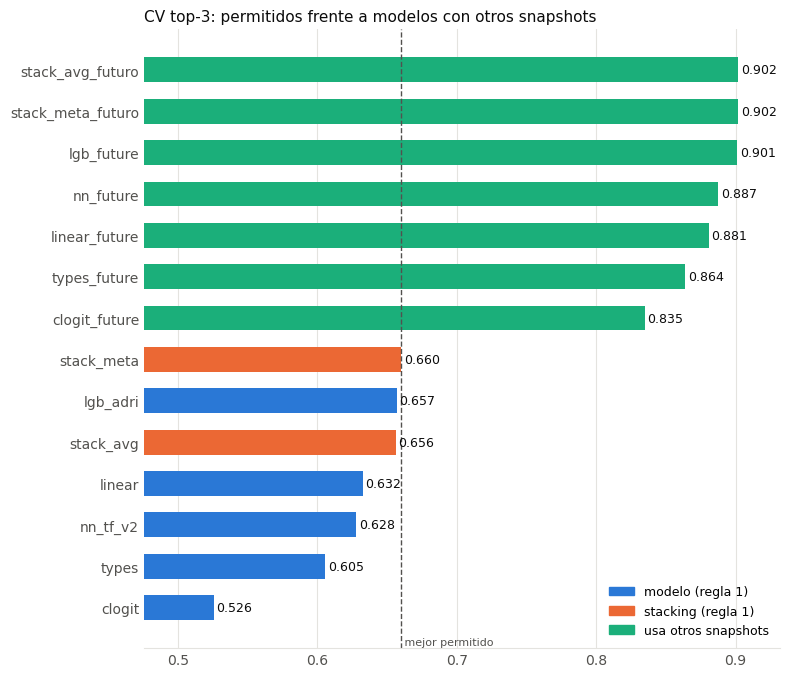

In [14]:
# Gráfico: azul = modelo (regla 1), naranja = stacking (regla 1), verde agua = usa otros snapshots
AGUA = "#1baf7a"
r = comp["CV top-3"].sort_values()
col = [AGUA if m in FUT_NOMBRES else (NARANJA if m in STACKS else AZUL) for m in r.index]
fig, ax = plt.subplots(figsize=(8, 0.42 * len(r) + 1))
ax.barh(r.index, r.values, height=0.6, color=col)
ax.set_xlim(max(0, r.min() - 0.05), min(1, r.max() + 0.03))
for y, v in enumerate(r.values):
    ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=9, color=TINTA)
mp = resumen["CV top-3"].max()
ax.axvline(mp, color=TINTA2, lw=1, ls="--")
ax.text(mp, -0.9, " mejor permitido", fontsize=8, color=TINTA2)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(REJILLA); ax.tick_params(colors=TINTA2, length=0)
ax.grid(axis="x", color=REJILLA, lw=0.8); ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=AZUL, label="modelo (regla 1)"), Patch(color=NARANJA, label="stacking (regla 1)"),
                   Patch(color=AGUA, label="usa otros snapshots")],
          frameon=False, loc="lower right", fontsize=9)
ax.set_title("CV top-3: permitidos frente a modelos con otros snapshots", loc="left", color=TINTA, fontsize=11)
plt.tight_layout(); plt.show()

In [15]:
# Mismo modelo con y sin otros snapshots: cuánto aporta la información temporal
pares = [(b, f) for b, f in [("lgb_adri", "lgb_future"), ("nn_tf_v2", "nn_future"), ("linear", "linear_future"),
                             ("clogit", "clogit_future"), ("types", "types_future"),
                             ("stack_meta", "stack_meta_futuro"), ("stack_avg", "stack_avg_futuro")]
         if b in HA and f in HA]
ganancia = pd.DataFrame([{"modelo": b, "futuro": f, "CV regla 1": HA[b].mean(), "CV futuro": HA[f].mean(),
                          "ganancia": HA[f].mean() - HA[b].mean(),
                          "peor atco regla 1": pa.loc[b].min(), "peor atco futuro": pa.loc[f].min()} for b, f in pares])
display(ganancia.style.format({c: "{:.4f}" for c in ganancia.columns if c not in ("modelo", "futuro")} | {"ganancia": "{:+.4f}"}))
mejor_fut = HF.mean().idxmax() if FUT_NOMBRES else None
if mejor_fut:
    techo_fut = HA[FUT_NOMBRES].max(axis=1).mean()
    print(f"Mejor con otros snapshots: {mejor_fut} ({HF[mejor_fut].mean():.4f}); algún modelo futuro acierta: {techo_fut:.3f}")
    # ¿dónde gana el futuro? por tipo de tarea correcta
    tf = pd.DataFrame({"mejor permitido": H.groupby("task_index")[resumen["CV top-3"].idxmax()].mean(),
                       "mejor futuro": HF.join(H.task_index).groupby("task_index")[mejor_fut].mean(),
                       "n": H.task_index.value_counts()})
    tf.index = [TIPOS[t] for t in tf.index]
    tf["ganancia"] = tf["mejor futuro"] - tf["mejor permitido"]
    display(tf[tf.n >= 30].sort_values("ganancia", ascending=False).style.format(
        {"mejor permitido": "{:.3f}", "mejor futuro": "{:.3f}", "ganancia": "{:+.3f}", "n": "{:.0f}"}))

,modelo,futuro,CV regla 1,CV futuro,ganancia,peor atco regla 1,peor atco futuro
0,lgb_adri,lgb_future,0.6569,0.9010,+0.2441,0.5704,0.7692
1,nn_tf_v2,nn_future,0.6279,0.8874,+0.2594,0.5664,0.7456
2,linear,linear_future,0.6323,0.8807,+0.2483,0.5423,0.7189
3,clogit,clogit_future,0.5255,0.8347,+0.3091,0.4447,0.6800
4,types,types_future,0.6054,0.8639,+0.2585,0.5319,0.7057
5,stack_meta,stack_meta_futuro,0.6600,0.9016,+0.2416,0.5802,0.7544
6,stack_avg,stack_avg_futuro,0.6562,0.9019,+0.2457,0.5712,0.7633


Mejor con otros snapshots: stack_avg_futuro (0.9019); algún modelo futuro acierta: 0.947


,mejor permitido,mejor futuro,n,ganancia
qos,0.156,0.782,257,+0.626
exit_cond,0.156,0.766,448,+0.609
exit_conflict_res,0.188,0.756,197,+0.569
entry_conflict_res,0.032,0.581,31,+0.548
conflict_res,0.405,0.872,390,+0.467
exit_coord,0.089,0.549,745,+0.460
return_to_route,0.475,0.872,937,+0.397
non_conformance,0.605,0.907,86,+0.302
entry_coord,0.436,0.725,1068,+0.288
zone_conflict,0.740,0.929,2121,+0.189


## 7. Resumen

In [16]:
best = resumen["CV top-3"].idxmax()
print(f"Modelos evaluados: {len(MODELOS)} solos + {len(STACKS)} stacks")
print(f"Mejor modelo solo: {mejor_solo} ({resumen.loc[mejor_solo, 'CV top-3']:.4f})")
for s in STACKS:
    print(f"{s:10s}: {resumen.loc[s, 'CV top-3']:.4f}  ({resumen.loc[s, 'vs mejor solo']:+.4f} vs mejor solo, "
          f"peor atco {resumen.loc[s, 'peor atco']:.3f})")
print("Stack evaluado con:", ", ".join(STACK_REAL) if STACK_REAL else "composición DESCONOCIDA (no se pudo rehacer)")
print(f"Techo (algún modelo acierta): {techo:.3f}   ·   todos fallan: {todos_fallan:.3f}")
gan = resumen.loc[best, "vs mejor solo"]
print("\nCandidata a envío:", f"sub_{best}.csv" if best in STACKS or tiene(best) else best,
      "" if gan >= 0.003 or best == mejor_solo else
      f"(ojo: solo {gan:+.4f} sobre {mejor_solo}; la diferencia puede ser ruido -> envío seguro: sub_{mejor_solo}.csv)")
if FUT_NOMBRES:
    print(f"\nCon otros snapshots: mejor {mejor_fut} = {HF[mejor_fut].mean():.4f} "
          f"({HF[mejor_fut].mean() - resumen['CV top-3'].max():+.4f} sobre el mejor con regla 1) -> futuro/submissions/sub_{mejor_fut.replace('_futuro', '')}.csv")

Modelos evaluados: 5 solos + 2 stacks
Mejor modelo solo: lgb_adri (0.6569)
stack_avg : 0.6562  (-0.0008 vs mejor solo, peor atco 0.571)
stack_meta: 0.6600  (+0.0031 vs mejor solo, peor atco 0.580)
Stack evaluado con: lgb_adri, nn_tf_v2, types
Techo (algún modelo acierta): 0.787   ·   todos fallan: 0.213

Candidata a envío: sub_stack_meta.csv 

Con otros snapshots: mejor stack_avg_futuro = 0.9019 (+0.2418 sobre el mejor con regla 1) -> futuro/submissions/sub_stack_avg.csv
